# M5 Retail Demand Forecasting — Notebook 3: LightGBM Model

**This notebook:** train and evaluate the LightGBM demand model properly: strong baselines, three validation folds, honest hyper-parameter tuning, a cold-start check, quantile forecasts and error analysis.

| | |
|---|---|
| **Inputs** | `features_h28.parquet`, `feature_config.json` (folds), `m5_sample_long.parquet`, `m5_series_stats.parquet` |
| **Outputs** | `lgbm_final_h28.txt`, `lgbm_config_h28.json`, `preds_lgbm_h28.parquet` |
| **Libraries** | pandas, numpy, lightgbm, matplotlib |

**Contents:** (1) setup, (2) evaluation framework, (3) baselines, (4) LightGBM with default settings, (5) tuning, (6) the `item_id` question, (7) quantile models, (8) error analysis, (9) final model and saving, (10) findings.

In Notebook 2 LightGBM was only a small tool for the feature ablation (300 trees, one fold). Here it is the actual model. Running the whole notebook takes roughly 25–40 minutes (about 35 LightGBM fits).

---
## 1. Setup and data

We use the h = 28 feature table from Notebook 2 and the **same three folds** defined there (`feature_config.json`). Using identical folds and rows for every model is what makes the later comparison with Chronos-2 and TFT fair.

In [1]:
import json, time, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

import lightgbm as lgb

SEED = 42
H = 28

def find_file(name):
    for root in [Path(".")] + ([Path("..")] if not Path("data").exists() else []) + [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            hits = list(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Run Notebooks 1 and 2 first (on Kaggle, add their output as an input).")

FEAT_PATH  = find_file("features_h28.parquet")
CFG_PATH   = find_file("feature_config.json")
STATS_PATH = find_file("m5_series_stats.parquet")
LONG_PATH  = find_file("m5_sample_long.parquet")
OUT = Path("/kaggle/working/processed") if Path("/kaggle/working").exists() else (Path("../data/processed") if (not Path("data").exists() and Path("../data").exists()) else Path("data/processed"))
OUT.mkdir(parents=True, exist_ok=True)
print("Features:", FEAT_PATH, "\nOutput  :", OUT)

Features: ../input/notebooks/syedzaidalii/02-feature-engineering/processed/features_h28.parquet 
Output  : /kaggle/working/processed


In [2]:
cfg = json.loads(CFG_PATH.read_text())
dfm = pd.read_parquet(FEAT_PATH)
dfm["date"] = pd.to_datetime(dfm["date"])

groups = cfg["feature_groups_by_horizon"][str(H)]
FEATURES = [c for g in groups.values() for c in g]
CAT_COLS = cfg["categorical_features"]

folds = [{"fold": f["fold"], "train_end": pd.Timestamp(f["train_end"]),
          "valid_start": pd.Timestamp(f["valid_start"]), "valid_end": pd.Timestamp(f["valid_end"])}
         for f in cfg["folds"]]
FOLD = {f["fold"]: f for f in folds}

print(f"Rows: {len(dfm):,} | Features: {len(FEATURES)} | Series: {dfm['id'].nunique()}")
print("Categorical dtypes:", {c: str(dfm[c].dtype) for c in CAT_COLS})
for f in folds:
    print(f"Fold {f['fold']}: train_end={f['train_end'].date()} | valid {f['valid_start'].date()} -> {f['valid_end'].date()}")

# Boolean mask of the validation rows of each fold (computed once, reused)
VA = {f["fold"]: dfm["date"].between(f["valid_start"], f["valid_end"]).to_numpy() for f in folds}
print({k: int(v.sum()) for k, v in VA.items()}, "<- valid rows per fold")

Rows: 1,458,418 | Features: 37 | Series: 999
Categorical dtypes: {'item_id': 'category', 'dept_id': 'category', 'cat_id': 'category', 'store_id': 'category', 'event_type': 'category'}
Fold 1: train_end=2016-03-27 | valid 2016-03-28 -> 2016-04-24
Fold 2: train_end=2016-02-28 | valid 2016-02-29 -> 2016-03-27
Fold 3: train_end=2016-01-31 | valid 2016-02-01 -> 2016-02-28
{1: 27972, 2: 27972, 3: 27960} <- valid rows per fold


---
## 2. Evaluation framework

All models are judged with the same functions.

| Metric | Definition | Why |
|---|---|---|
| **WAPE** | `sum(abs(actual - forecast)) / sum(actual)` | main metric; defined at zero; lower is better |
| **MAE** | mean absolute error (units) | easy to interpret |
| **Bias %** | `(sum(forecast) - sum(actual)) / sum(actual)` | over- or under-forecasting; positive means over-forecast |
| **MASE** | absolute error scaled by the series' seasonal-naive error | below 1 means better than seasonal naive |
| **WAPE 7d / 28d sums** | WAPE after summing each series over 7- or 28-day blocks | closer to inventory lead-time demand; daily noise partly cancels |

Daily WAPE is dominated by sparse series where even a good forecast is wrong on most days. Inventory reorder points depend on demand over a **lead time**, not on one day, so aggregated WAPE is reported as well.

The MASE scale is computed from the **training period only** (`mean |sales - lag_28|` per series) so that it does not leak validation information.

In [3]:
def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.abs(y - p).sum() / y.sum()) if y.sum() > 0 else float("nan")

def agg_wape(va, y, p, days):
    """WAPE after summing each series over blocks of `days` days."""
    blk = ((va["date"] - va["date"].min()).dt.days.to_numpy() // days)
    tmp = pd.DataFrame({"id": va["id"].to_numpy(), "blk": blk, "y": y, "p": p})
    g = tmp.groupby(["id", "blk"])[["y", "p"]].sum()
    return float(np.abs(g["y"] - g["p"]).sum() / g["y"].sum())

_scale_cache = {}
def mase_scale(fold):
    """Seasonal-naive error per series from the training period only (no leakage)."""
    if fold not in _scale_cache:
        tr = dfm.loc[dfm["date"] <= FOLD[fold]["train_end"], ["id", "sales", f"lag_{H}"]].dropna()
        _scale_cache[fold] = (tr["sales"] - tr[f"lag_{H}"]).abs().groupby(tr["id"]).mean()
    return _scale_cache[fold]

def evaluate(fold, p):
    va = dfm.loc[VA[fold]]
    y = va["sales"].to_numpy(float); p = np.asarray(p, float)
    sc = va["id"].map(mase_scale(fold)).to_numpy(float)
    ok = sc > 0
    return {
        "WAPE": wape(y, p),
        "MAE": float(np.abs(y - p).mean()),
        "bias_%": float((p.sum() - y.sum()) / y.sum() * 100),
        "MASE": float((np.abs(y - p)[ok] / sc[ok]).mean()),
        "WAPE_7d_sum": agg_wape(va, y, p, 7),
        "WAPE_28d_sum": agg_wape(va, y, p, 28),
    }

RUNS = {}   # RUNS[model_name][fold] = {"metrics": {...}, "pred": array}

def record(name, fold, pred):
    RUNS.setdefault(name, {})[fold] = {"metrics": evaluate(fold, pred), "pred": np.asarray(pred, float)}

def summarize(names, fold_list=(1, 2, 3)):
    rows = []
    for n in names:
        fl = [f for f in fold_list if f in RUNS[n]]
        r = {"model": n}
        for k in ["WAPE", "MAE", "bias_%", "MASE", "WAPE_7d_sum", "WAPE_28d_sum"]:
            r[k] = np.mean([RUNS[n][f]["metrics"][k] for f in fl])
        for f in fl:
            r[f"WAPE_f{f}"] = RUNS[n][f]["metrics"]["WAPE"]
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")

print("Evaluation functions ready")

Evaluation functions ready


---
## 3. Baselines

Machine learning is only worth its complexity if it beats strong simple methods. In Notebook 2 we compared only with seasonal naive (`lag_28`), which is weak because it copies one noisy day.

| Baseline | Definition |
|---|---|
| Seasonal naive (`lag_28`) | sales of the same weekday 28 days earlier |
| **Moving average** (`roll_mean_28`) | mean of the last 28 days up to the forecast origin |
| Same-weekday mean | mean of the last four same-weekday values (`lag_28, 35, 42, 49`) |
| **Croston-SBA** | classic method for intermittent demand |

**Croston-SBA.** A plain average performs poorly on zero-heavy data, so Croston smooths two quantities separately: the demand size `z` when a sale occurs, and the interval `p` between sales. The daily forecast is `z / p`; the SBA variant multiplies by `(1 - alpha/2)` to remove a known bias. It is computed on the raw sales matrix, updated after each day, and the forecast for target date `t` uses only information up to `t - 28`.

In [4]:
def _to_wide(values, ids, dates):
    arr = np.asarray(values, dtype="float64").reshape(len(ids), len(dates)).T
    return pd.DataFrame(arr, index=dates, columns=ids)

def croston_sba(S, alpha=0.1):
    """S: DataFrame (dates x ids), NaN = unavailable (skip). Returns forecast made at end of each day."""
    arr = S.to_numpy(dtype="float64"); n, m = arr.shape
    z = np.full(m, np.nan); p = np.full(m, np.nan); q = np.zeros(m)
    F = np.zeros((n, m))
    for i in range(n):
        y = arr[i]; obs = ~np.isnan(y)
        q = q + obs                                   # observed periods since last demand
        dem = obs & (y > 0)
        init = dem & np.isnan(z)
        upd  = dem & ~np.isnan(z)
        z = np.where(init, y, z);  p = np.where(init, q, p)
        z = np.where(upd, z + alpha * (y - z), z)
        p = np.where(upd, p + alpha * (q - p), p)
        q = np.where(dem, 0.0, q)
        F[i] = np.where(np.isnan(z), 0.0, (1 - alpha / 2) * z / p)
    return pd.DataFrame(F, index=S.index, columns=S.columns)

# ---- load the raw sales (the feature table is not a full panel: unavailable rows were removed) ----
raw = pd.read_parquet(LONG_PATH, columns=["id", "date", "sales", "is_available"])
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.sort_values(["id", "date"]).reset_index(drop=True)
ids = raw["id"].drop_duplicates().tolist()
dates = pd.DatetimeIndex(np.sort(raw["date"].unique()))
assert len(raw) == len(ids) * len(dates)

S = _to_wide(raw["sales"].where(raw["is_available"]), ids, dates)
t0 = time.time()
CR = croston_sba(S, alpha=0.1).shift(H)           # forecast for target t uses data up to (t - H)
print(f"Croston-SBA computed in {time.time()-t0:.1f}s")

cr_long = pd.DataFrame({"id": np.repeat(np.array(ids, dtype=object), len(dates)),
                        "date": np.tile(dates.to_numpy(), len(ids)),
                        "croston": CR.to_numpy(dtype="float32").T.ravel()})
cr_long["id"] = cr_long["id"].astype(dfm["id"].dtype)
n0 = len(dfm)
dfm = dfm.merge(cr_long, on=["id", "date"], how="left", validate="one_to_one")
assert len(dfm) == n0
del raw, S, CR, cr_long
print("Croston column joined:", dfm["croston"].notna().mean().round(4), "non-null share")

Croston-SBA computed in 0.1s
Croston column joined: 1.0 non-null share


In [5]:
BASELINES = {
    "naive_lag28":       f"lag_{H}",
    "moving_avg_28":     "roll_mean_28",
    "same_weekday_mean": "same_weekday_mean",
    "croston_sba":       "croston",
}
for name, col in BASELINES.items():
    for f in folds:
        record(name, f["fold"], dfm.loc[VA[f["fold"]], col].fillna(0).to_numpy())

base_tbl = summarize(list(BASELINES))
base_tbl

,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3
model,,,,,,,,,
naive_lag28,0.9506,1.3083,-1.8412,1.0842,0.4841,0.3035,0.9630,0.9623,0.9265
moving_avg_28,0.8082,1.1124,-4.2852,0.9562,0.4395,0.3217,0.8138,0.8261,0.7847
same_weekday_mean,0.8311,1.1439,-3.5522,0.9776,0.4333,0.3122,0.8329,0.8470,0.8135
croston_sba,0.8468,1.1654,-2.7230,1.0045,0.4705,0.3498,0.8464,0.8624,0.8317


**Result (3-fold average).**

| Baseline | WAPE | 7d-sum WAPE | 28d-sum WAPE |
|---|---|---|---|
| Seasonal naive | 0.951 | 0.484 | 0.304 |
| **Moving average 28** | **0.808** | 0.439 | 0.322 |
| Same-weekday mean | 0.831 | 0.433 | 0.312 |
| Croston-SBA | 0.847 | 0.470 | 0.350 |

The 28-day moving average is the strongest baseline on daily WAPE and is the benchmark the ML model has to beat. For reference, forecasting zero everywhere gives WAPE = 1.0, so the seasonal naive baseline (0.951) is barely better than that.

---
## 4. LightGBM with default settings

**Objective.** Sales are non-negative counts with many exact zeros and occasional spikes, so we use the **Tweedie** objective. Its `tweedie_variance_power` lies between 1 (Poisson-like) and 2 (Gamma-like); values between the two suit zero-heavy data. We start with 1.1.

**Training window.** The last 730 days before each fold's `train_end`.

**No early stopping.** Early stopping uses the validation set to decide when to stop, so validation would influence the model. We use a fixed number of trees and use the validation folds only for measurement.

In [6]:
def base_params(**over):
    p = dict(objective="tweedie", tweedie_variance_power=1.1, learning_rate=0.05,
             num_leaves=63, min_data_in_leaf=100, feature_fraction=0.8,
             bagging_fraction=0.8, bagging_freq=1, lambda_l2=0.0,
             n_estimators=400, random_state=SEED, verbose=-1)
    p.update(over)
    return p

def fit_fold(feats, fold, params, train_days=730):
    f = FOLD[fold]
    tr = ((dfm["date"] <= f["train_end"]) & (dfm["date"] > f["train_end"] - pd.Timedelta(days=train_days))).to_numpy()
    cats = [c for c in feats if c in CAT_COLS]
    m = lgb.LGBMRegressor(**params)
    m.fit(dfm.loc[tr, feats], dfm.loc[tr, "sales"], categorical_feature=cats if cats else "auto")
    return m, m.predict(dfm.loc[VA[fold], feats])

def run_config(name, feats, params, train_days=730, fold_list=(1, 2, 3), verbose=True):
    for fo in fold_list:
        t0 = time.time()
        _, pred = fit_fold(feats, fo, params, train_days)
        record(name, fo, pred)
        if verbose:
            mt = RUNS[name][fo]["metrics"]
            print(f"  [{name}] fold {fo}: WAPE={mt['WAPE']:.4f}  WAPE_7d={mt['WAPE_7d_sum']:.4f}  ({time.time()-t0:.0f}s)")

DEFAULT = base_params()
run_config("lgbm_default", FEATURES, DEFAULT)
summarize(list(BASELINES) + ["lgbm_default"])

  [lgbm_default] fold 1: WAPE=0.7612  WAPE_7d=0.3684  (25s)
  [lgbm_default] fold 2: WAPE=0.7917  WAPE_7d=0.4158  (25s)
  [lgbm_default] fold 3: WAPE=0.7636  WAPE_7d=0.3941  (25s)


,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3
model,,,,,,,,,
naive_lag28,0.9506,1.3083,-1.8412,1.0842,0.4841,0.3035,0.9630,0.9623,0.9265
moving_avg_28,0.8082,1.1124,-4.2852,0.9562,0.4395,0.3217,0.8138,0.8261,0.7847
same_weekday_mean,0.8311,1.1439,-3.5522,0.9776,0.4333,0.3122,0.8329,0.8470,0.8135
croston_sba,0.8468,1.1654,-2.7230,1.0045,0.4705,0.3498,0.8464,0.8624,0.8317
lgbm_default,0.7722,1.0627,-2.4635,0.9466,0.3928,0.2778,0.7612,0.7917,0.7636


**Result (3-fold average, default settings).** WAPE 0.772 versus 0.808 for the moving average (about 4.5% lower); 7-day-sum WAPE 0.393 versus 0.439; 28-day-sum WAPE 0.278 versus 0.322; MASE 0.947; bias -2.5%. The model wins on every fold (fold WAPE 0.761 / 0.792 / 0.764), so the gain is not caused by a single favourable window. The gain is larger after aggregation than at daily level.

---
## 5. Hyper-parameter tuning without overfitting the validation folds

| Parameter | Meaning |
|---|---|
| `num_leaves` | complexity of each tree |
| `min_data_in_leaf` | minimum rows per leaf (larger = more conservative) |
| `feature_fraction` | share of features seen by each tree (regularisation) |
| `lambda_l2` | penalty on leaf weights |
| `tweedie_variance_power` | shape of the Tweedie distribution |
| `n_estimators` | number of trees |
| `train_days` | length of the training window (730 or 1,460) |

**Selection overfitting.** If we tried many settings on Fold 1 and picked the best, the winner would partly reflect noise in that fold. To avoid this:
1. tune on **Folds 2 and 3**,
2. confirm on **Fold 1**, which the tuning never saw,
3. accept the tuned model only if it also helps on Fold 1.

We use random search (8 trials) rather than a grid, which covers the space more efficiently for the same budget.

In [7]:
N_TRIALS = 8   # use 4 if time is short; 12-16 for a wider search

space = {
    "tweedie_variance_power": [1.05, 1.1, 1.2, 1.3, 1.5],
    "num_leaves":             [31, 63, 127],
    "min_data_in_leaf":       [50, 100, 300, 1000],
    "feature_fraction":       [0.6, 0.8, 1.0],
    "lambda_l2":              [0.0, 1.0, 10.0],
    "n_estimators":           [300, 500],
    "train_days":             [730, 1460],
}
rng = np.random.default_rng(SEED)
trials = []
for i in range(N_TRIALS):
    trials.append({k: rng.choice(v).item() for k, v in space.items()})

TUNE_FOLDS = (2, 3)
trial_log = []
for i, tr_cfg in enumerate(trials, 1):
    name = f"trial_{i}"
    td = int(tr_cfg["train_days"])
    params = base_params(**{k: v for k, v in tr_cfg.items() if k != "train_days"})
    t0 = time.time()
    run_config(name, FEATURES, params, train_days=td, fold_list=TUNE_FOLDS, verbose=False)
    sc = np.mean([RUNS[name][f]["metrics"]["WAPE"] for f in TUNE_FOLDS])
    trial_log.append({"trial": name, **tr_cfg, "WAPE_f2f3": sc, "seconds": round(time.time() - t0)})
    print(f"{name}: WAPE(f2,f3)={sc:.4f} | {tr_cfg}")

default_sc = np.mean([RUNS["lgbm_default"][f]["metrics"]["WAPE"] for f in TUNE_FOLDS])
print(f"\nDefault config WAPE(f2,f3) = {default_sc:.4f}")
tune_df = pd.DataFrame(trial_log).sort_values("WAPE_f2f3").reset_index(drop=True)
tune_df

trial_1: WAPE(f2,f3)=0.7774 | {'tweedie_variance_power': 1.05, 'num_leaves': 127, 'min_data_in_leaf': 300, 'feature_fraction': 0.8, 'lambda_l2': 1.0, 'n_estimators': 500, 'train_days': 730}
trial_2: WAPE(f2,f3)=0.7778 | {'tweedie_variance_power': 1.3, 'num_leaves': 31, 'min_data_in_leaf': 50, 'feature_fraction': 0.8, 'lambda_l2': 10.0, 'n_estimators': 500, 'train_days': 1460}
trial_3: WAPE(f2,f3)=0.7747 | {'tweedie_variance_power': 1.3, 'num_leaves': 127, 'min_data_in_leaf': 300, 'feature_fraction': 0.6, 'lambda_l2': 10.0, 'n_estimators': 300, 'train_days': 1460}
trial_4: WAPE(f2,f3)=0.7818 | {'tweedie_variance_power': 1.1, 'num_leaves': 31, 'min_data_in_leaf': 1000, 'feature_fraction': 1.0, 'lambda_l2': 1.0, 'n_estimators': 300, 'train_days': 1460}
trial_5: WAPE(f2,f3)=0.7762 | {'tweedie_variance_power': 1.2, 'num_leaves': 63, 'min_data_in_leaf': 100, 'feature_fraction': 0.6, 'lambda_l2': 0.0, 'n_estimators': 500, 'train_days': 1460}
trial_6: WAPE(f2,f3)=0.7802 | {'tweedie_variance_po

,trial,tweedie_variance_power,num_leaves,min_data_in_leaf,feature_fraction,lambda_l2,n_estimators,train_days,WAPE_f2f3,seconds
0,trial_8,1.3000,127,50,0.8000,1.0000,300,730,0.7702,46
1,trial_7,1.3000,63,50,1.0000,1.0000,500,1460,0.7734,101
2,trial_3,1.3000,127,300,0.6000,10.0000,300,1460,0.7747,85
3,trial_5,1.2000,63,100,0.6000,0.0000,500,1460,0.7762,112
4,trial_1,1.0500,127,300,0.8000,1.0000,500,730,0.7774,76
5,trial_2,1.3000,31,50,0.8000,10.0000,500,1460,0.7778,85
6,trial_6,1.0500,127,1000,0.6000,1.0000,300,1460,0.7802,89
7,trial_4,1.1000,31,1000,1.0000,1.0000,300,1460,0.7818,57


**Decision.** The best trial (WAPE 0.7702 on folds 2 and 3) beat the default (0.7776), so it is adopted. On Fold 1, which tuning did not see, WAPE improved from 0.7612 to 0.7568. The selected configuration uses `tweedie_variance_power = 1.3`, `num_leaves = 127`, `min_data_in_leaf = 50`, `feature_fraction = 0.8`, `lambda_l2 = 1.0`, 300 trees and a 730-day window.

In [8]:
best_row = tune_df.iloc[0]
use_tuned = bool(best_row["WAPE_f2f3"] < default_sc)

if use_tuned:
    BEST_TRAIN_DAYS = int(best_row["train_days"])
    BEST_PARAMS = base_params(**{k: (int(best_row[k]) if k in ("num_leaves", "min_data_in_leaf", "n_estimators") else float(best_row[k]))
                                 for k in ["tweedie_variance_power", "num_leaves", "min_data_in_leaf", "feature_fraction", "lambda_l2", "n_estimators"]})
    print("Best trial beats the default:", best_row["trial"])
else:
    BEST_TRAIN_DAYS, BEST_PARAMS = 730, DEFAULT
    print("No trial beat the default; keeping the default.")
print("Params:", {k: v for k, v in BEST_PARAMS.items() if k not in ("random_state", "verbose", "bagging_freq", "learning_rate", "objective")}, "| train_days:", BEST_TRAIN_DAYS)

# ---- Confirm on Fold 1 (not seen during tuning) ----
if use_tuned:
    run_config("lgbm_tuned", FEATURES, BEST_PARAMS, train_days=BEST_TRAIN_DAYS, fold_list=(1,))
    for f in (2, 3):
        RUNS.setdefault("lgbm_tuned", {})[f] = RUNS[best_row["trial"]][f]    # reuse the trial's results
else:
    for f in (1, 2, 3):
        RUNS.setdefault("lgbm_tuned", {})[f] = RUNS["lgbm_default"][f]

cmp = summarize(["lgbm_default", "lgbm_tuned"])
print("\nFold 1 (not seen by tuning): default =", round(RUNS["lgbm_default"][1]["metrics"]["WAPE"], 4),
      "| tuned =", round(RUNS["lgbm_tuned"][1]["metrics"]["WAPE"], 4))
cmp

Best trial beats the default: trial_8
Params: {'tweedie_variance_power': 1.3, 'num_leaves': 127, 'min_data_in_leaf': 50, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'lambda_l2': 1.0, 'n_estimators': 300} | train_days: 730
  [lgbm_tuned] fold 1: WAPE=0.7568  WAPE_7d=0.3651  (23s)

Fold 1 (not seen by tuning): default = 0.7612 | tuned = 0.7568


,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3
model,,,,,,,,,
lgbm_default,0.7722,1.0627,-2.4635,0.9466,0.3928,0.2778,0.7612,0.7917,0.7636
lgbm_tuned,0.7657,1.0539,-4.4149,0.9382,0.3906,0.2775,0.7568,0.7839,0.7565


**Interpretation.** Tuning is confirmed on the unseen fold, but the gain is small (about 0.6% relative in WAPE on Fold 1). It also moved the total bias from -2.5% to -4.4%: WAPE does not penalise under-forecasting much on zero-heavy data, so a WAPE-driven search can drift towards lower forecasts. Large improvements came from feature engineering, not from tuning. The bias is monitored in the later notebooks.

---
## 6. Is `item_id` safe to keep? (cold-start)

`item_id` contributed 17% of the importance in Notebook 2 and the series-info family improved WAPE by 0.024. `item_id` lets the model memorise individual items. A **new item** that was not in the training data has no meaningful `item_id`, so the feature cannot help it (cold-start problem).

We compare three variants with the tuned parameters on all folds:

| Variant | Features |
|---|---|
| `all` | all 37 features |
| `no_item_id` | without `item_id` |
| `no_ids` | without `item_id`, `dept_id`, `cat_id`, `store_id` (keeping `age_days`) |

**Rule fixed in advance:** if removing `item_id` raises the mean WAPE by less than 0.005 we drop it (a small accuracy loss for a more robust model); otherwise we keep it and document the limitation.

In [9]:
ID_COLS = ["item_id", "dept_id", "cat_id", "store_id"]
VARIANTS = {
    "var_all":        FEATURES,
    "var_no_item_id": [c for c in FEATURES if c != "item_id"],
    "var_no_ids":     [c for c in FEATURES if c not in ID_COLS],
}
for name, feats in VARIANTS.items():
    if name == "var_all":
        for f in (1, 2, 3):
            RUNS.setdefault(name, {})[f] = RUNS["lgbm_tuned"][f]
        continue
    print(name, f"({len(feats)} features)")
    run_config(name, feats, BEST_PARAMS, train_days=BEST_TRAIN_DAYS)

var_tbl = summarize(list(VARIANTS))
var_tbl["n_features"] = [len(v) for v in VARIANTS.values()]
var_tbl

var_no_item_id (36 features)
  [var_no_item_id] fold 1: WAPE=0.7784  WAPE_7d=0.3856  (20s)
  [var_no_item_id] fold 2: WAPE=0.8060  WAPE_7d=0.4341  (20s)
  [var_no_item_id] fold 3: WAPE=0.7693  WAPE_7d=0.3994  (19s)
var_no_ids (33 features)
  [var_no_ids] fold 1: WAPE=0.7816  WAPE_7d=0.3858  (19s)
  [var_no_ids] fold 2: WAPE=0.8153  WAPE_7d=0.4366  (19s)
  [var_no_ids] fold 3: WAPE=0.7715  WAPE_7d=0.3998  (18s)


,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3,n_features
model,,,,,,,,,,
var_all,0.7657,1.0539,-4.4149,0.9382,0.3906,0.2775,0.7568,0.7839,0.7565,37
var_no_item_id,0.7846,1.0798,-1.8499,0.9749,0.4064,0.2879,0.7784,0.8060,0.7693,36
var_no_ids,0.7895,1.0866,-1.2208,0.9902,0.4074,0.2874,0.7816,0.8153,0.7715,33


In [10]:
w_all  = var_tbl.loc["var_all", "WAPE"]
w_noid = var_tbl.loc["var_no_item_id", "WAPE"]
w_noids = var_tbl.loc["var_no_ids", "WAPE"]
print(f"WAPE: all={w_all:.4f} | no_item_id={w_noid:.4f} (diff {w_noid-w_all:+.4f}) | no_ids={w_noids:.4f} (diff {w_noids-w_all:+.4f})")

if w_noid - w_all < 0.005:
    FINAL_VARIANT = "var_no_item_id"
    print("\n-> cost of dropping item_id < 0.005: the FINAL model is built without item_id (cold-start safe).")
else:
    FINAL_VARIANT = "var_all"
    print("\n-> item_id gives a clear gain (>= 0.005). Keeping it; the cold-start limitation must be documented.")

FINAL_FEATURES = VARIANTS[FINAL_VARIANT]
for f in (1, 2, 3):
    RUNS.setdefault("lgbm_final", {})[f] = RUNS[FINAL_VARIANT][f]
print("Final features:", len(FINAL_FEATURES))

WAPE: all=0.7657 | no_item_id=0.7846 (diff +0.0188) | no_ids=0.7895 (diff +0.0237)

-> item_id gives a clear gain (>= 0.005). Keeping it; the cold-start limitation must be documented.
Final features: 37


**Result.**

| Variant | WAPE | Bias |
|---|---|---|
| all features | 0.7657 | -4.4% |
| no `item_id` | 0.7846 | -1.8% |
| no identifiers | 0.7895 | -1.2% |

Removing `item_id` costs 0.019 WAPE, well above the 0.005 threshold, so it is kept. **Limitation:** the model cannot be expected to work well for items that are not in the training data. A natural improvement is to replace `item_id` with item-history statistics. The variant without identifiers has a lower bias and could serve as a fallback model.

---
## 7. Quantile models (P10, P50, P90)

A point forecast is not enough for inventory decisions; we also want a range. A quantile model with `alpha = 0.9` predicts the value below which 90% of outcomes fall.

**Pinball loss** is asymmetric: for `alpha = 0.9`, under-forecasting is penalised with weight 0.9 and over-forecasting with weight 0.1. This is what makes the model learn an upper bound.

We report
- **pinball loss** per quantile (lower is better),
- **calibration**: the share of actuals at or below each predicted quantile (should be close to alpha),
- **coverage** of the P10-P90 interval (target about 80%).

The three quantile models are trained separately, so predictions are sorted within each row to avoid crossing quantiles.

Note for inventory use: quantiles of daily demand cannot simply be added to obtain a quantile of lead-time demand (the sum of quantiles is not the quantile of the sum), so this is only a daily-level quality check.

In [11]:
QUANTILES = [0.1, 0.5, 0.9]
qparams_base = {k: v for k, v in BEST_PARAMS.items() if k != "tweedie_variance_power"}

def pinball(y, q, a):
    d = np.asarray(y, float) - np.asarray(q, float)
    return float(np.mean(np.maximum(a * d, (a - 1) * d)))

QF = 1   # quantile models are trained on Fold 1
fo = FOLD[QF]
tr = ((dfm["date"] <= fo["train_end"]) & (dfm["date"] > fo["train_end"] - pd.Timedelta(days=BEST_TRAIN_DAYS))).to_numpy()
cats = [c for c in FINAL_FEATURES if c in CAT_COLS]
y1 = dfm.loc[VA[QF], "sales"].to_numpy(float)

qpred = {}
for a in QUANTILES:
    t0 = time.time()
    m = lgb.LGBMRegressor(**{**qparams_base, "objective": "quantile", "alpha": a})
    m.fit(dfm.loc[tr, FINAL_FEATURES], dfm.loc[tr, "sales"], categorical_feature=cats if cats else "auto")
    qpred[a] = np.clip(m.predict(dfm.loc[VA[QF], FINAL_FEATURES]), 0, None)
    print(f"alpha={a}: trained in {time.time()-t0:.0f}s")

# non-crossing: sort the quantiles within each row
Q = np.sort(np.vstack([qpred[a] for a in QUANTILES]), axis=0)
qpred = {a: Q[i] for i, a in enumerate(QUANTILES)}

mean_pred_f1 = RUNS["lgbm_final"][QF]["pred"]
q_rows = [{"quantile": a, "pinball": pinball(y1, qpred[a], a),
           "share_actual_below_pred_%": float((y1 <= qpred[a]).mean() * 100)} for a in QUANTILES]
q_tbl = pd.DataFrame(q_rows).set_index("quantile")
coverage = float(((y1 >= qpred[0.1]) & (y1 <= qpred[0.9])).mean() * 100)
print(f"\nP10-P90 interval coverage (daily): {coverage:.1f}%  (target ~ 80%)")
print(f"P50 WAPE = {wape(y1, qpred[0.5]):.4f}  vs  Tweedie-mean WAPE = {wape(y1, mean_pred_f1):.4f}")
print("Average interval width (P90-P10):", round(float((qpred[0.9] - qpred[0.1]).mean()), 3), "units")
q_tbl

alpha=0.1: trained in 28s
alpha=0.5: trained in 24s
alpha=0.9: trained in 23s

P10-P90 interval coverage (daily): 82.2%  (target ~ 80%)
P50 WAPE = 0.7117  vs  Tweedie-mean WAPE = 0.7568
Average interval width (P90-P10): 3.014 units


,pinball,share_actual_below_pred_%
quantile,,
0.1000,0.1333,54.1470
0.5000,0.4911,61.9262
0.9000,0.3156,88.8996


**Result (Fold 1).**

| Quantile | Pinball loss | Share of actuals at or below the forecast |
|---|---|---|
| P10 | 0.133 | 54.1% |
| P50 | 0.491 | 61.9% |
| P90 | 0.316 | 88.9% |

The P90 forecast is well calibrated (88.9% against a 90% target) and the P10-P90 interval has 82.2% coverage (target 80%), with an average width of 3.0 units.

For P10 and P50 the "share at or below" is far above 10% and 50% because more than half of the days have zero sales, so predicted quantiles are often 0 and an actual of 0 counts as "at or below". This is a property of discrete zero-heavy data, not a bug.

The P50 forecast has a lower WAPE (0.712) than the mean forecast (0.757), but a median forecast tends to under-forecast total demand and WAPE alone hides this. We therefore keep the Tweedie **mean** as the point forecast and use quantiles only to describe risk.

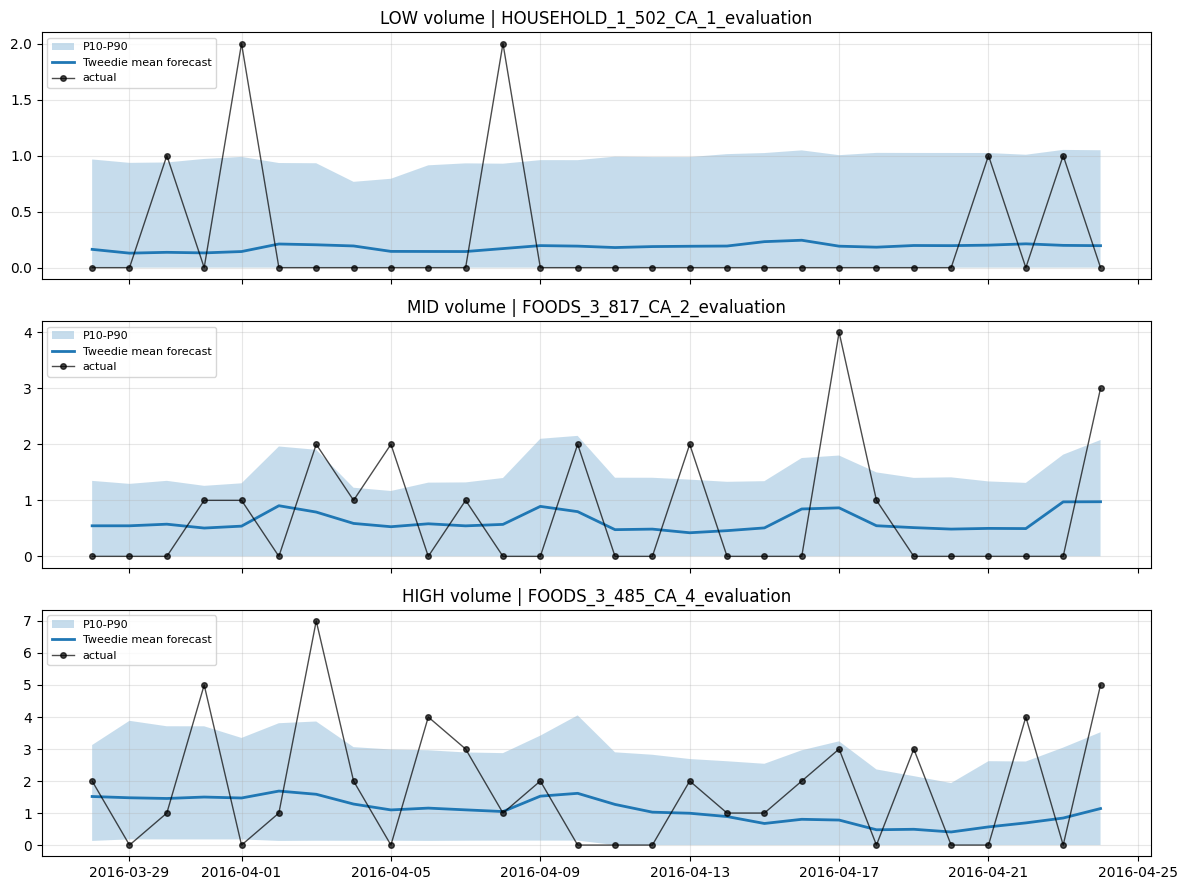

In [12]:
va1 = dfm.loc[VA[QF], ["id", "date", "vol_tier", "sales"]].reset_index(drop=True)
va1["p10"], va1["p50"], va1["p90"] = qpred[0.1], qpred[0.5], qpred[0.9]
va1["mean"] = mean_pred_f1

tot = va1.groupby(["vol_tier", "id"])["sales"].sum()
picks = []
for tier in ["low", "mid", "high"]:
    s = tot.loc[tier].sort_values()
    picks.append((tier, s.index[len(s) // 2]))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (tier, sid) in zip(axes, picks):
    d = va1[va1["id"] == sid].sort_values("date")
    ax.fill_between(d["date"], d["p10"], d["p90"], alpha=0.25, label="P10-P90")
    ax.plot(d["date"], d["mean"], lw=2, label="Tweedie mean forecast")
    ax.plot(d["date"], d["sales"], "o-", lw=1, ms=4, color="black", alpha=0.7, label="actual")
    ax.set_title(f"{tier.upper()} volume | {sid}")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

---
## 8. Error analysis

One overall number hides where the model works and where it does not. We break the Fold 1 error down by demand class, volume tier, category, store and weekday. For each segment we report its share of total sales, the WAPE of the model and of the moving average, and the bias.

In [13]:
stats = pd.read_parquet(STATS_PATH).set_index("id")
ea = dfm.loc[VA[1], ["id", "date", "vol_tier", "store_id", "cat_id", "dow", "sales"]].reset_index(drop=True)
ea = ea.rename(columns={"sales": "y"})
ea["p"] = RUNS["lgbm_final"][1]["pred"]
ea["naive"] = RUNS["naive_lag28"][1]["pred"]
ea["ma28"] = RUNS["moving_avg_28"][1]["pred"]
ea["demand_class"] = ea["id"].map(stats["demand_class"])
ea["store_id"] = ea["store_id"].astype(str); ea["cat_id"] = ea["cat_id"].astype(str)

def seg_table(df, by):
    rows = []
    for k, g in df.groupby(by):
        rows.append({by: k, "series": g["id"].nunique(), "sales_share_%": g["y"].sum() / df["y"].sum() * 100,
                     "WAPE_model": wape(g["y"], g["p"]), "WAPE_naive": wape(g["y"], g["naive"]),
                     "WAPE_ma28": wape(g["y"], g["ma28"]),
                     "bias_%": (g["p"].sum() - g["y"].sum()) / g["y"].sum() * 100 if g["y"].sum() > 0 else np.nan})
    return pd.DataFrame(rows).set_index(by)

seg_results = {}
for by in ["demand_class", "vol_tier", "cat_id", "store_id", "dow"]:
    seg_results[by] = seg_table(ea, by)
    print(f"\n=== By {by} ===")
    display(seg_results[by])


=== By demand_class ===


,series,sales_share_%,WAPE_model,WAPE_naive,WAPE_ma28,bias_%
demand_class,,,,,,
erratic,34,11.9424,0.6903,0.9672,0.8051,8.3866
intermittent,708,40.1378,0.9310,1.1001,0.9535,-3.1876
lumpy,196,21.9859,0.8621,1.1475,0.9462,-4.9359
smooth,61,25.9339,0.4285,0.5923,0.4894,0.5352



=== By vol_tier ===


,series,sales_share_%,WAPE_model,WAPE_naive,WAPE_ma28,bias_%
vol_tier,,,,,,
high,333,70.6103,0.6356,0.8635,0.7139,1.8149
low,333,9.0954,1.2428,1.3441,1.2260,-8.3464
mid,333,20.2943,0.9605,1.1384,0.9767,-8.6065



=== By cat_id ===


,series,sales_share_%,WAPE_model,WAPE_naive,WAPE_ma28,bias_%
cat_id,,,,,,
FOODS,451,59.9995,0.7072,0.9206,0.7862,0.1425
HOBBIES,224,16.3411,0.8736,1.1003,0.8915,-6.4386
HOUSEHOLD,324,23.6594,0.8018,0.9757,0.8300,-1.0889



=== By store_id ===


,series,sales_share_%,WAPE_model,WAPE_naive,WAPE_ma28,bias_%
store_id,,,,,,
CA_1,258,26.9986,0.7310,0.8985,0.7693,-2.4704
CA_2,245,20.8668,0.8250,1.0590,0.9133,-5.6791
CA_3,262,38.3685,0.6846,0.9148,0.7573,4.6997
CA_4,234,13.7661,0.9052,1.0783,0.9077,-8.5386



=== By dow ===


,series,sales_share_%,WAPE_model,WAPE_naive,WAPE_ma28,bias_%
dow,,,,,,
0,999,13.7558,0.7599,0.9714,0.8168,-2.3243
1,999,12.3258,0.8122,1.0319,0.9046,1.3879
2,999,11.8776,0.8277,1.0412,0.9348,3.1608
3,999,12.0460,0.7818,1.0105,0.8772,1.9502
4,999,14.2169,0.7658,0.9719,0.8130,-3.2510
5,999,16.8126,0.7093,0.9206,0.7205,0.4772
6,999,18.9653,0.6936,0.8637,0.7197,-6.8757


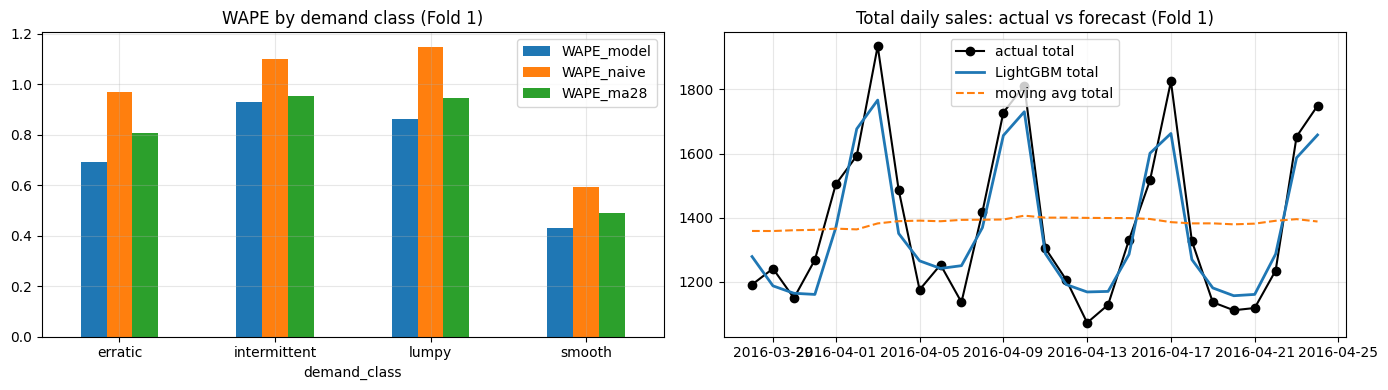

Aggregate-level daily WAPE (daily totals over all series): LightGBM=0.0535 | MA28=0.1581


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

s = seg_results["demand_class"][["WAPE_model", "WAPE_naive", "WAPE_ma28"]]
s.plot.bar(ax=axes[0]); axes[0].set_title("WAPE by demand class (Fold 1)"); axes[0].tick_params(axis="x", rotation=0)

daily = ea.groupby("date")[["y", "p", "ma28"]].sum()
axes[1].plot(daily.index, daily["y"], "o-", color="black", label="actual total")
axes[1].plot(daily.index, daily["p"], lw=2, label="LightGBM total")
axes[1].plot(daily.index, daily["ma28"], lw=1.5, ls="--", label="moving avg total")
axes[1].set_title("Total daily sales: actual vs forecast (Fold 1)"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Aggregate-level daily WAPE (daily totals over all series): LightGBM={wape(daily['y'], daily['p']):.4f} | MA28={wape(daily['y'], daily['ma28']):.4f}")

**Findings (Fold 1; WAPE of LightGBM versus moving average).**

| Segment | LightGBM | Moving avg |
|---|---|---|
| Smooth (26% of sales) | 0.429 | 0.489 |
| Erratic (12%) | 0.690 | 0.805 |
| Lumpy (22%) | 0.862 | 0.946 |
| **Intermittent (40%)** | **0.931** | **0.953** |
| High-volume tier (71%) | 0.636 | 0.714 |
| Mid tier (20%) | 0.961 | 0.977 |
| **Low tier (9%)** | **1.243** | **1.226** |

The model helps most where volume is high and demand is regular, and is roughly equal to the baseline on sparse series (the intermittent class is 40% of sales). By category the gain is about 10% for FOODS and about 2% for HOBBIES. For CA_4 the model and baseline are tied (0.905 vs 0.908) with a bias of -8.5%, while CA_3 has +4.7% bias, which points to store-level effects the model does not fully capture. Sunday, the strongest day, is under-forecast by 6.9%. On the daily total over all series, LightGBM has a WAPE of 0.054 against 0.158 for the moving average, so at aggregate level the model is much better.

---
## 9. Final model and saved artefacts

1. **Predictions** of all models for the three folds are saved with identical rows. Chronos-2 and TFT are evaluated on the same rows in Notebook 4.
2. **The final model** is trained on the last 730 days up to the end of the training data (2016-04-24) with the selected parameters and saved to a text file.
3. **The configuration** (parameters, feature list, training window) is saved so the model can be reproduced.

The folds' numbers were obtained with models that never saw the validation days. The final model has now seen those days, so its score on the folds must not be reported; its only honest score is on the untouched holdout (Notebook 5).

In [15]:
# ---- 1) Predictions (same rows, all models) ----
pred_rows = []
for fo_ in (1, 2, 3):
    base = dfm.loc[VA[fo_], ["id", "date", "vol_tier", "sales"]].reset_index(drop=True)
    base["fold"] = fo_
    for name in ["naive_lag28", "moving_avg_28", "same_weekday_mean", "croston_sba", "lgbm_default", "lgbm_final"]:
        base[name] = RUNS[name][fo_]["pred"]
    if fo_ == QF:
        base["q10"], base["q50"], base["q90"] = qpred[0.1], qpred[0.5], qpred[0.9]
    pred_rows.append(base)
preds_df = pd.concat(pred_rows, ignore_index=True)
preds_df.to_parquet(OUT / "preds_lgbm_h28.parquet", index=False)
print("Saved predictions:", preds_df.shape)

# ---- 2) Final model: fit on all available history ----
last = dfm["date"].max()
trf = (dfm["date"] > last - pd.Timedelta(days=BEST_TRAIN_DAYS)).to_numpy()
cats = [c for c in FINAL_FEATURES if c in CAT_COLS]
final_model = lgb.LGBMRegressor(**BEST_PARAMS)
final_model.fit(dfm.loc[trf, FINAL_FEATURES], dfm.loc[trf, "sales"], categorical_feature=cats if cats else "auto")
final_model.booster_.save_model(str(OUT / "lgbm_final_h28.txt"))
print(f"Final model trained on {int(trf.sum()):,} rows ({dfm.loc[trf,'date'].min().date()} -> {last.date()})")

# ---- 3) Config ----
model_cfg = {
    "horizon": H, "objective": BEST_PARAMS["objective"], "train_days": BEST_TRAIN_DAYS,
    "params": {k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in BEST_PARAMS.items()},
    "final_variant": FINAL_VARIANT, "features": FINAL_FEATURES, "categorical": cats,
    "tuned": use_tuned, "tuning_trials": N_TRIALS,
}
(OUT / "lgbm_config_h28.json").write_text(json.dumps(model_cfg, indent=2))
print("Saved:", sorted(p.name for p in OUT.iterdir() if "lgbm" in p.name))

Saved predictions: (83904, 14)
Final model trained on 705,512 rows (2014-04-26 -> 2016-04-24)
Saved: ['lgbm_config_h28.json', 'lgbm_final_h28.txt', 'preds_lgbm_h28.parquet']


---
## 10. Findings and decisions (our run)

| # | Observation | Interpretation | Decision |
|---|---|---|---|
| 1 | Best baseline: 28-day moving average (WAPE 0.808) | the real benchmark, not seasonal naive | the ML model must beat this |
| 2 | LightGBM 3-fold WAPE 0.766 (tuned), consistent across folds (0.757 / 0.784 / 0.756) | about 5% lower than the benchmark | ML is justified, but gains are modest at daily level |
| 3 | 7d-sum WAPE 0.391 vs 0.439; 28d-sum 0.278 vs 0.322 | gain grows with aggregation | evaluate and use forecasts at lead-time level |
| 4 | Tuning: 0.7776 -> 0.7702 on folds 2-3; 0.7612 -> 0.7568 on Fold 1 | tuning is genuine but small; bias moved to -4.4% | adopt tuned parameters; monitor bias |
| 5 | Removing `item_id` raises WAPE by 0.019 | item identity matters | keep; document cold-start limitation |
| 6 | P90 calibration 88.9%; P10-P90 coverage 82.2% | upper quantile and interval are well calibrated | usable for risk; not for lead-time sums directly |
| 7 | Weak segments: intermittent class, low tier, HOBBIES, CA_4 | sparse series are hard | segment-wise reporting; consider alternatives for sparse series |
| 8 | Sunday under-forecast by 6.9% | peak day is underestimated | monitor weekday bias |

---
## Summary of results (machine-readable)

In [16]:
def tbl(names):
    t = summarize(names)
    return {n: {k: round(float(v), 4) for k, v in t.loc[n].items()} for n in t.index}

best_base = base_tbl["WAPE"].idxmin()
summary = {
    "rows": int(len(dfm)), "n_features_all": len(FEATURES), "n_features_final": len(FINAL_FEATURES),
    "baselines_3fold_avg": tbl(list(BASELINES)),
    "best_baseline": best_base,
    "lgbm_default_vs_tuned_vs_final": tbl(["lgbm_default", "lgbm_tuned", "lgbm_final"]),
    "tuning": {"n_trials": N_TRIALS, "best_trial_WAPE_f2f3": round(float(tune_df.iloc[0]["WAPE_f2f3"]), 4),
               "default_WAPE_f2f3": round(float(default_sc), 4), "tuned_used": use_tuned,
               "best_params": {k: v for k, v in model_cfg["params"].items() if k in ("tweedie_variance_power", "num_leaves", "min_data_in_leaf", "feature_fraction", "lambda_l2", "n_estimators")},
               "train_days": BEST_TRAIN_DAYS,
               "fold1_default_vs_tuned": [round(RUNS["lgbm_default"][1]["metrics"]["WAPE"], 4), round(RUNS["lgbm_tuned"][1]["metrics"]["WAPE"], 4)]},
    "item_id_variants": tbl(list(VARIANTS)),
    "final_variant": FINAL_VARIANT,
    "quantiles_fold1": {"pinball": q_tbl["pinball"].round(4).to_dict(),
                        "share_actual_below_pred_%": q_tbl["share_actual_below_pred_%"].round(1).to_dict(),
                        "coverage_p10_p90_%": round(coverage, 1),
                        "p50_WAPE": round(wape(y1, qpred[0.5]), 4), "mean_WAPE": round(wape(y1, mean_pred_f1), 4),
                        "avg_interval_width": round(float((qpred[0.9] - qpred[0.1]).mean()), 3)},
    "error_analysis_fold1": {by: seg_results[by][["sales_share_%", "WAPE_model", "WAPE_naive", "WAPE_ma28", "bias_%"]].round(3).to_dict("index")
                             for by in ["demand_class", "vol_tier", "cat_id", "store_id"]},
    "weekday_bias_%_fold1": seg_results["dow"]["bias_%"].round(2).to_dict(),
    "aggregate_daily_total_WAPE_fold1": {"lgbm": round(wape(daily["y"], daily["p"]), 4), "ma28": round(wape(daily["y"], daily["ma28"]), 4)},
}
print(json.dumps(summary, indent=2, default=str))

{
  "rows": 1458418,
  "n_features_all": 37,
  "n_features_final": 37,
  "baselines_3fold_avg": {
    "naive_lag28": {
      "WAPE": 0.9506,
      "MAE": 1.3083,
      "bias_%": -1.8412,
      "MASE": 1.0842,
      "WAPE_7d_sum": 0.4841,
      "WAPE_28d_sum": 0.3035,
      "WAPE_f1": 0.963,
      "WAPE_f2": 0.9623,
      "WAPE_f3": 0.9265
    },
    "moving_avg_28": {
      "WAPE": 0.8082,
      "MAE": 1.1124,
      "bias_%": -4.2852,
      "MASE": 0.9562,
      "WAPE_7d_sum": 0.4395,
      "WAPE_28d_sum": 0.3217,
      "WAPE_f1": 0.8138,
      "WAPE_f2": 0.8261,
      "WAPE_f3": 0.7847
    },
    "same_weekday_mean": {
      "WAPE": 0.8311,
      "MAE": 1.1439,
      "bias_%": -3.5522,
      "MASE": 0.9776,
      "WAPE_7d_sum": 0.4333,
      "WAPE_28d_sum": 0.3122,
      "WAPE_f1": 0.8329,
      "WAPE_f2": 0.847,
      "WAPE_f3": 0.8135
    },
    "croston_sba": {
      "WAPE": 0.8468,
      "MAE": 1.1654,
      "bias_%": -2.723,
      "MASE": 1.0045,
      "WAPE_7d_sum": 0.4705,
    